In [1]:
%%time
import random
from tqdm import tqdm
from scipy import stats
from sklearn.linear_model import LinearRegression
import matplotlib as mpl
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import torchsummary
from datetime import datetime
import numpy as np
import pandas as pd
import xarray as xr
from sklearn.preprocessing import minmax_scale
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import gc
import os, sys
sys.path.insert(0,'/home/mingyu_seong/Works/func/python')
import mg

rs = 100
def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(rs)

def minmax_scale_train_based(train_data, *other_data, eps=1e-8):
    data_min = train_data.min().item()
    data_max = train_data.max().item()
    scale = lambda x: (x - data_min) / (data_max - data_min + eps)
    return (scale(train_data),) + tuple(scale(d) for d in other_data)

def standard_scale_train_based(train_data, *other_data, eps=1e-8):
    data_mean = train_data.mean().item()
    data_std = train_data.std().item()
    scale = lambda x: (x - data_mean) / (data_std + eps)
    return (scale(train_data),) + tuple(scale(d) for d in other_data)

#=================================================================================================
# Define Model (NN)
#=================================================================================================
class NNModel(nn.Module):
    def __init__(self):
        super(NNModel, self).__init__()
        self.dense1 = nn.Linear(train_x.shape[1], 16)
        self.dense2 = nn.Linear(16, 8)
        self.output_frp = nn.Linear(8, 1)

        self.dropout = nn.Dropout(0.2)
        self.batch_norm1 = nn.BatchNorm1d(16)
        self.batch_norm2 = nn.BatchNorm1d(8)

    def forward(self, x):
        x = F.relu(self.batch_norm1(self.dense1(x)))
        x = self.dropout(x)
        x = F.relu(self.batch_norm2(self.dense2(x)))
        return self.output_frp(x)

#=================================================================================================
# GPU setting
#=================================================================================================
device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")

CPU times: user 1.51 s, sys: 194 ms, total: 1.71 s
Wall time: 1.75 s


### 1) GPP & Reco & NEE

In [2]:
from netCDF4 import Dataset

# 1. input4MIPs
pin = '/home/share/KCP/yena/data/mole-fraction-of-carbon-dioxide-in-air/'
fhist0 = 'mole-fraction-of-carbon-dioxide-in-air_input4MIPs_GHGConcentrations_CMIP_UoM-CMIP-1-2-0_gn-15x360deg_000001-201412.nc'
f1190 = 'mole-fraction-of-carbon-dioxide-in-air_input4MIPs_GHGConcentrations_ScenarioMIP_UoM-IMAGE-ssp119-1-2-0_gn-15x360deg_201501-250012.nc'
f1260 = 'mole-fraction-of-carbon-dioxide-in-air_input4MIPs_GHGConcentrations_ScenarioMIP_UoM-IMAGE-ssp126-1-2-0_gn-15x360deg_201501-250012.nc'
f2450 = 'mole-fraction-of-carbon-dioxide-in-air_input4MIPs_GHGConcentrations_ScenarioMIP_UoM-MESSAGE-GLOBIOM-ssp245-1-2-0_gn-15x360deg_201501-250012.nc'
f3700 = 'mole-fraction-of-carbon-dioxide-in-air_input4MIPs_GHGConcentrations_ScenarioMIP_UoM-AIM-ssp370-1-2-0_gn-15x360deg_201501-250012.nc'
f5850 = 'mole-fraction-of-carbon-dioxide-in-air_input4MIPs_GHGConcentrations_ScenarioMIP_UoM-REMIND-MAGPIE-ssp585-1-2-0_gn-15x360deg_201501-250012.nc'

fhist = mg.cdo('monmean',input=pin+fhist0,options='-s -L -O')
f119  = mg.cdo('monmean',input=pin+f1190,options='-s -L -O')
f126  = mg.cdo('monmean',input=pin+f1260,options='-s -L -O')
f245  = mg.cdo('monmean',input=pin+f2450,options='-s -L -O')
f370  = mg.cdo('monmean',input=pin+f3700,options='-s -L -O')
f585  = mg.cdo('monmean',input=pin+f5850,options='-s -L -O')

# 1) Historical (0 to 2014)
ncid  = Dataset(fhist,mode='r')
hist  = ncid.variables['mole_fraction_of_carbon_dioxide_in_air'][:]
yhist = hist.mean(axis=1)
ncid.close()
# 2) SSP119
ncid    = Dataset(f119,mode='r')
ssp119  = ncid.variables['mole_fraction_of_carbon_dioxide_in_air'][:]
yssp119 = ssp119.mean(axis=1)
ncid.close()
# 3) SSP126
ncid    = Dataset(f126,mode='r')
ssp126  = ncid.variables['mole_fraction_of_carbon_dioxide_in_air'][:]
yssp126 = ssp126.mean(axis=1)
ncid.close()
# 4) SSP245
ncid    = Dataset(f245,mode='r')
ssp245  = ncid.variables['mole_fraction_of_carbon_dioxide_in_air'][:]
yssp245 = ssp245.mean(axis=1)
ncid.close()
# 5) SSP370
ncid    = Dataset(f370,mode='r')
ssp370  = ncid.variables['mole_fraction_of_carbon_dioxide_in_air'][:]
yssp370 = ssp370.mean(axis=1)
ncid.close()
# 6) SSP585
ncid    = Dataset(f585,mode='r')
ssp585  = ncid.variables['mole_fraction_of_carbon_dioxide_in_air'][:]
yssp585 = ssp585.mean(axis=1)
ncid.close()
mg.unlink([fhist,f119,f126,f245,f370,f585])

In [3]:
ncid = xr.open_dataset('./gpp_CESM_mon_ssp585_200101-210012.nc')
ts_time = np.squeeze(ncid['time'].data)
ts_time = np.array([dt.year for dt in ts_time])
ts_gpp = np.squeeze(ncid['gpp'])
ncid.close() ; del ncid
ncid = xr.open_dataset('./tas_CESM_mon_ssp585_200101-210012.nc')
ts_tas = np.squeeze(ncid['tas'])#.data)
ncid.close() ; del ncid
ncid = xr.open_dataset('./pr_CESM_mon_ssp585_200101-210012.nc')
ts_pr = np.squeeze(ncid['pr'])
ncid.close() ; del ncid
ncid = xr.open_dataset('./mrsos_CESM_mon_ssp585_200101-210012.nc')
ts_sm = np.squeeze(ncid['mrsos'])
ncid.close() ; del ncid
ncid = xr.open_dataset('./rsds_CESM_mon_ssp585_200101-210012.nc')
ts_sw = np.squeeze(ncid['rsds'])
ncid.close() ; del ncid
ts_co2 = xr.DataArray(np.concatenate([yhist[(2001*12):(2015*12)].data,yssp585[0:(86*12)].data]),
                      dims=['time'], coords={'time': ts_tas.time.data},)

In [4]:
#--- Clim
syr = 2001
eyr = 2100
nyr = eyr-syr+1

#--- Clim
csyr = 2001
ceyr = 2020
clim_tas = ts_tas.sel(time=slice(str(csyr),str(ceyr))).groupby('time.month').mean()
ts_clim_tas = xr.DataArray(np.tile(clim_tas.data, nyr), dims=['time'], coords={'time': ts_tas.time.data},)
clim_pr = ts_pr.sel(time=slice(str(csyr),str(ceyr))).groupby('time.month').mean()
ts_clim_pr = xr.DataArray(np.tile(clim_pr.data, nyr), dims=['time'], coords={'time': ts_tas.time.data},)
clim_sm = ts_sm.sel(time=slice(str(csyr),str(ceyr))).groupby('time.month').mean()
ts_clim_sm = xr.DataArray(np.tile(clim_sm.data, nyr), dims=['time'], coords={'time': ts_tas.time.data},)
clim_sw = ts_sw.sel(time=slice(str(csyr),str(ceyr))).groupby('time.month').mean()
ts_clim_sw = xr.DataArray(np.tile(clim_sw.data, nyr), dims=['time'], coords={'time': ts_tas.time.data},)
clim_co2 = ts_co2.sel(time=slice(str(csyr),str(ceyr))).groupby('time.month').mean()
ts_clim_co2 = xr.DataArray(np.tile(clim_co2.data, nyr), dims=['time'], coords={'time': ts_tas.time.data},)

In [5]:
feature_names_ordered = [
    'T_clim','P_clim','SM_clim',               # Clims
    'T_anom','P_anom','SM_anom','SW_anom',     # Anomaly
    'SW',                                      # Saturation
    'CO2', 'TCO2', 'SMCO2',                    # CO2 fertilization
    'TSQ']                                     # Stress

#--- Read data
C0 = 1.
raw_data_arrays = {}
raw_data_arrays['T_clim']  = ts_clim_tas
raw_data_arrays['P_clim']  = ts_clim_pr
raw_data_arrays['SM_clim'] = ts_clim_sm
raw_data_arrays['SW_clim'] = ts_clim_sw
raw_data_arrays['T_anom']  = ts_tas - ts_clim_tas
raw_data_arrays['P_anom']  = ts_pr - ts_clim_pr
raw_data_arrays['SM_anom'] = ts_sm - ts_clim_sm
raw_data_arrays['SW_anom'] = ts_sw - ts_clim_sw

#--- Saturation terms
raw_data_arrays['T']   = ts_tas / ( np.nanmean(raw_data_arrays['T_clim'].data) + ts_tas)
raw_data_arrays['P']   = ts_pr  / ( np.nanmean(raw_data_arrays['P_clim'].data)  + ts_pr) 
raw_data_arrays['SM']  = ts_sm  / ( np.nanmean(raw_data_arrays['SM_clim'].data) + ts_sm) 
raw_data_arrays['SW']  = ts_sw  / ( np.nanmean(raw_data_arrays['SW_clim'].data) + ts_sw) # np.log(ts_sw)
# raw_data_arrays['SW']  = np.log(ts_sw)
raw_data_arrays['CO2'] = np.log(ts_co2/C0)

#--- Interaction terms
raw_data_arrays['TCO2']  = raw_data_arrays['T_anom'] * np.log(ts_co2/C0)
raw_data_arrays['SMCO2'] = raw_data_arrays['SM_anom'] * np.log(ts_co2/C0)
raw_data_arrays['TSM']   = raw_data_arrays['T_anom'] * raw_data_arrays['SM_anom']
raw_data_arrays['TSQ']   = raw_data_arrays['T_anom']**2
raw_data_arrays['SMSQ']  = raw_data_arrays['SM_anom']**2

#--- input & label
features_ds = xr.Dataset()
for feature_name in feature_names_ordered:
    da = raw_data_arrays[feature_name]
    features_ds[feature_name] = da
label_da = ts_gpp

#--- Add Month of Year
moy = []
for imon in np.arange(12):
    mon = imon + 1
    moy.append(float(np.sin(2*np.pi/12*mon)))
features_ds['MOY'] = xr.DataArray(moy*nyr,
                        dims=['time'],
                        coords={'time': ts_tas.time.data})
feature_names_ordered = feature_names_ordered + ['MOY']

#--- Combined inputs
combined_features_da = features_ds.to_array(dim='variable')

데이터셋으로 통합 및 스태킹 중...


 / Epoch 100/1000,                            Train Loss: 0.6534990668296814,               Val Loss: 0.3797420561313629
Early stopping!


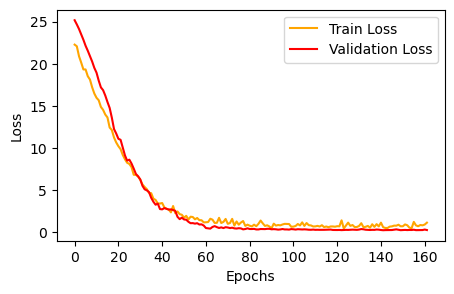

In [6]:
device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")

train_start  = None ; train_end  = None
train_start0 = None ; train_end0 = None
train_start1 = None ; train_end1 = None
valid_start  = None ; valid_end  = None
test_start   = None ; test_end   = None

train_start = '2001' ; train_end = '2020'
valid_start = '2021' ; valid_end = '2025'
test_start  = '2026' ; test_end  = '2100'

#--- Train
if train_start0 is not None and train_start1 is not None:
    # 1) First period
    train_features_da_part0 = combined_features_da.sel(time=slice(train_start0, train_end0))
    train_label_da_part0 = label_da.sel(time=slice(train_start0, train_end0))
    # 2) Second period
    train_features_da_part1 = combined_features_da.sel(time=slice(train_start1, train_end1))
    train_label_da_part1 = label_da.sel(time=slice(train_start1, train_end1))
    # 3) Merge periods
    train_features_da = xr.concat([train_features_da_part0, train_features_da_part1], dim='time')
    train_label_da = xr.concat([train_label_da_part0, train_label_da_part1], dim='time')
else:
    train_features_da = combined_features_da.sel(time=slice(train_start, train_end))
    train_label_da = label_da.sel(time=slice(train_start, train_end))

#--- Validation
valid_features_da = combined_features_da.sel(time=slice(valid_start, valid_end))      
valid_label_da = label_da.sel(time=slice(valid_start, valid_end))

#--- Test
test_features_da = combined_features_da.sel(time=slice(test_start, test_end))      
test_label_da = label_da.sel(time=slice(test_start, test_end))

stacked_train_features_list, stacked_valid_features_list, stacked_test_features_list = [],[],[]
for i, feature_name in enumerate(feature_names_ordered):
    stacked_train_feature_array = train_features_da[i].values
    stacked_valid_feature_array  = valid_features_da[i].values
    stacked_test_feature_array  = test_features_da[i].values
    stacked_train_features_list.append(stacked_train_feature_array)
    stacked_valid_features_list.append(stacked_valid_feature_array)
    stacked_test_features_list.append(stacked_test_feature_array)

#--- Separate data (train / validation / test)
train_x = np.transpose(np.vstack(stacked_train_features_list))
valid_x = np.transpose(np.vstack(stacked_valid_features_list))
test_x  = np.transpose(np.vstack(stacked_test_features_list))
train_y = train_label_da.values
valid_y = valid_label_da.values
test_y  = test_label_da.values

#--- Normalize variables
for i in np.arange(train_x.shape[1]):
    train_x[:,i], valid_x[:,i], test_x[:,i] = standard_scale_train_based(train_x[:,i], valid_x[:,i], test_x[:,i])

# Convert numpy arrays to PyTorch tensors
train_x = torch.tensor(train_x, dtype=torch.float32, device=device)
train_y = torch.tensor(train_y, dtype=torch.float32, device=device)
valid_x = torch.tensor(valid_x, dtype=torch.float32, device=device)
valid_y = torch.tensor(valid_y, dtype=torch.float32, device=device)
test_x = torch.tensor(test_x, dtype=torch.float32, device=device)
test_y = torch.tensor(test_y, dtype=torch.float32, device=device)

# Dataset and DataLoader for batching
train_data = TensorDataset(train_x, train_y)
valid_data = TensorDataset(valid_x, valid_y)
test_data = TensorDataset(test_x, test_y)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
valid_loader = DataLoader(valid_data, batch_size=32, shuffle=False)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False)

#=================================================================================================
# Model Training
#=================================================================================================
model = NNModel().to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 1000
patience = 20
best_val_loss = float('inf')
epochs_no_improve = 0

train_losses, val_losses = [],[]
for epoch in range(EPOCHS):
    model.train()
    train_loss = 0
    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model(batch_x)
        loss = criterion(outputs.squeeze(), batch_y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    model.eval()
    val_loss = 0
    with torch.no_grad():
        for batch_x, batch_y in valid_loader:
            outputs = model(batch_x)
            loss = criterion(outputs.squeeze(), batch_y)
            val_loss += loss.item()

    train_losses.append(train_loss/len(train_loader))
    val_losses.append(val_loss/len(valid_loader))
    if (epoch+1) % 100 == 0:
        print(f" / Epoch {epoch+1}/{EPOCHS},              \
              Train Loss: {train_loss/len(train_loader)}, \
              Val Loss: {val_loss/len(valid_loader)}")

    # Early stopping check
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        # torch.save(model.state_dict(), owdir + wfou)
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print("Early stopping!")
            break

#--- Plotting train / validation loss
inner_grid = gridspec.GridSpec(1, 1, wspace=0.2, hspace=0.5)
fig = plt.figure(figsize=(5,3))
ax = fig.add_subplot(inner_grid[0])
ax.plot(range(epoch+1), train_losses, label='Train Loss', color='orange')
ax.plot(range(epoch+1), val_losses, label='Validation Loss', color='red')
plt.ylabel('Loss')
plt.xlabel('Epochs')
ax.legend()
plt.show()

In [ ]:
#--- Inference
model.eval()
y_pred = []
with torch.no_grad():
    for batch_x, _ in valid_loader:
        outputs = model(batch_x)
        y_pred.extend(outputs.squeeze().cpu().numpy())
pred = np.array(y_pred)

#--- Data array
pred_y = xr.DataArray(pred,
                        dims=['time'],
                        coords={'time': valid_label_da.time.data},
                        attrs={'long_name': 'Predicted GPP',
                               'units': 'gC/m^2/day',})# '_FillValue': 1e+30})

test_y = xr.DataArray(valid_label_da,
                      dims=['time'],
                      coords={'time': valid_label_da.time.data},
                      attrs={'long_name': 'Predicted GPP',
                              'units': 'gC/m^2/day',})# '_FillValue': 1e+30})